# Mask first, scale second

**Objective:** Decode quality flags and reproduce reflectance and temperature scaling from actual digital numbers.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

Landsat digital numbers are encoded measurements. A zero fill value must not become a plausible temperature after scaling. We reject QA_PIXEL bits 0–5: fill, dilated cloud, cirrus, cloud, cloud shadow and snow; any nonzero QA_RADSAT is conservatively rejected. Optical bands additionally require nonzero DN, and temperature requires nonzero thermal DN. Missing values remain null.

Surface reflectance is **DN × 0.0000275 − 0.2**. Temperature in Celsius is **DN × 0.00341802 + 149 − 273.15**. The reflectance offset matters when computing normalized differences; it does not cancel in their denominator.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=03_qa_scaling.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
for r in data:
    clear = (int(r["qa_pixel_dn"]) & 63) == 0 and r["qa_radsat_dn"] == 0
    optical = clear and all(r[k + "_dn"] > 0 for k in ("blue", "green", "red", "nir08"))
    assert bool(r["valid"]) == optical
    if optical:
        assert abs(r["red"] - (r["red_dn"] * .0000275 - .2)) < 1e-6
    if r["temperature_c"] is not None:
        assert abs(r["temperature_c"] - (r["lwir11_dn"] * .00341802 + 149 - 273.15)) < 1e-6
print("QA/scaling checks passed for", len(data), "actual sampled pixels.")

QA/scaling checks passed for 6890 actual sampled pixels.


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

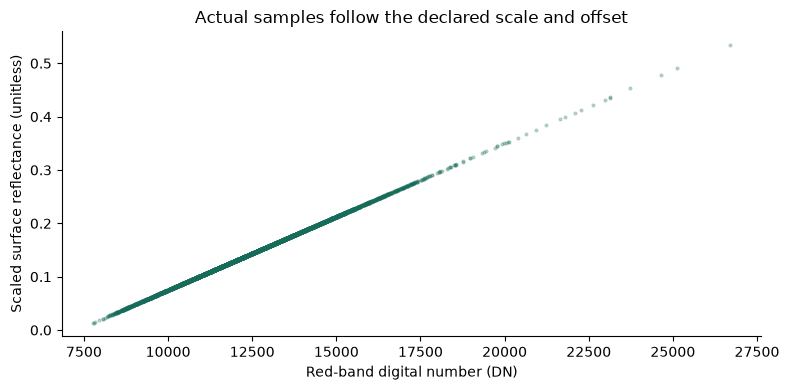

In [3]:
plt.scatter(values("red_dn"), values("red"), s=4, alpha=.25, color="#176c59")
plt.xlabel("Red-band digital number (DN)"); plt.ylabel("Scaled surface reflectance (unitless)")
plt.title("Actual samples follow the declared scale and offset")
plt.tight_layout(); plt.show()

## Interpret and extend

Calculate the temperature that zero DN would produce if fill were accidentally scaled. Explain why an arithmetic result alone cannot establish that a measurement is valid. Inspect which QA flags your selected scene actually contains.

## Sources and attribution

- [USGS, How do I use a scale factor with Landsat Level-2 science products?](https://www.usgs.gov/faqs/how-do-i-use-a-scale-factor-landsat-level-2-science-products).
- [USGS, Landsat Collection 2 quality assessment bands](https://www.usgs.gov/landsat-missions/landsat-collection-2-quality-assessment-bands).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.